# Mini-Project 2: Solar Micro-Grid Dispatch Planner
**OOP with Python: Assignment 1 (Advent 2026)**

## The problem in one paragraph
A rural health centre in Kasese runs a micro-grid. Every day it must satisfy **two demand constraints** using energy from **solar panels (x)** and **batteries (y)**:

| Constraint | Equation |
|---|---|
| Daytime load (D1, kWh) | `3x + 2y = D1` |
| Critical-equipment load (D2, kWh) | `4x + 1y = D2` |

In matrix form this is **A · [x, y] = [D1, D2]**, where `A = [[3, 2], [4, 1]]`.

## How this notebook is organised
| Part | What we do |
|---|---|
| 0 | Imports and settings (change numbers here, nowhere else) |
| 1 | The `MicroGrid` class + well-posedness check (determinant and condition number) |
| 2 | Two input modes: interactive `input()` with validation, and a 30-day CSV |
| 3 | Solve 30 days: Python loop vs one vectorised call, timed with `timeit` |
| 4 | Detect and handle **infeasible days** (negative x or y) |
| 5 | Statistics: which source is more volatile? |
| 6 | Cost model (UGX) |
| 7 | Stacked bar chart with a cost axis |
| Ext. A | `HybridMicroGrid`: add diesel, 3×3 system, linear dependence |
| Ext. B | Monte Carlo sensitivity analysis |

**Design rule used throughout:** every piece of logic is a small function or method with a docstring, and every setting lives in Part 0, so you can reuse the code for another health centre by changing only the settings.

---
## Part 0: Imports and settings

In [1]:
import statistics                      # mean, variance, stdev (Part 5)
import timeit                          # timing (Part 3)
from pathlib import Path               # clean file paths

import numpy as np                     # arrays and maths
import pandas as pd                    # tables (DataFrames) and CSV
import matplotlib.pyplot as plt        # charts
from scipy.linalg import solve, null_space   # solve A·v = b ; find the "free" directions of A
from scipy.optimize import nnls        # non-negative least squares (Part 4)

# ---------- SETTINGS: change these to reuse the notebook ----------
COEFF_MATRIX  = [[3, 2],               # 3x + 2y = D1
                 [4, 1]]               # 4x + 1y = D2
SOURCE_NAMES  = ("solar", "battery")   # names of the unknowns, in the order x, y
N_DAYS        = 30                     # days of demand to generate/load
SEED          = 42                     # makes the "random" CSV identical every run
CSV_PATH      = Path("demand_30_days.csv")
START_DATE    = "2026-09-01"           # first day in the CSV

SOLAR_PRICE   = 150                    # UGX per kWh (illustrative)
BATTERY_PRICE = 450                    # UGX per kWh (illustrative)

TOLERANCE     = 1e-9                   # ignore negatives smaller than this (floating-point dust)

---
## Part 1: The `MicroGrid` class

### Why check the system *before* solving?
Solving `A·v = d` only makes sense if `A` has a **unique** answer. Two numbers tell us:

* **Determinant** `det(A)`
  * `det = 0` → the equations are *dependent* (one is a rescaled copy of the other). There is **no unique solution**: either none or infinitely many.
  * `det ≠ 0` → exactly **one** solution exists.
* **Condition number** `cond(A)`
  * It measures **how much the answer can wobble when the demands wobble.** A rough rule: a 1% error in the demands can become up to `cond × 1%` error in x and y.
  * `cond ≈ 1` is superb, `cond` in the thousands means the answers are unreliable, and `cond = ∞` means singular.

The class below runs these checks automatically when you create a `MicroGrid`.

For `A = [[3,2],[4,1]]`: `det = 3·1 − 2·4 = −5` (not zero, so one unique solution; the sign only tells us the orientation, the size is what matters).

In [2]:
class MicroGrid:
    """A micro-grid whose daily dispatch is the solution of a square linear system A·v = d.

    Attributes
    ----------
    A : np.ndarray       the coefficient matrix
    labels : tuple       names of the unknowns, e.g. ("solar", "battery")
    det : float          determinant of A
    cond : float         condition number of A
    is_singular : bool   True if A does not have full rank (no unique solution)
    """

    def __init__(self, matrix=COEFF_MATRIX, labels=SOURCE_NAMES):
        self.A = np.array(matrix, dtype=float)
        if self.A.ndim != 2 or self.A.shape[0] != self.A.shape[1]:
            raise ValueError("The coefficient matrix must be square (same rows as columns).")
        self.size = self.A.shape[0]
        self.labels = tuple(labels)

        # The two well-posedness numbers
        self.det = np.linalg.det(self.A)
        self.cond = np.linalg.cond(self.A)
        # matrix_rank is a more trustworthy singularity test than "det == 0"
        self.is_singular = np.linalg.matrix_rank(self.A) < self.size

    # ---------- diagnostics ----------
    def report(self):
        """Print the determinant, condition number and what they mean."""
        print("Coefficient matrix A:")
        print(self.A)
        print(f"\nDeterminant      : {self.det:.4f}")
        print(f"Condition number : {self.cond:.4f}")
        if self.is_singular:
            print("\n-> SINGULAR: the equations are dependent. No unique solution exists.")
        elif self.cond < 10:
            print("\n-> WELL-POSED and WELL-CONDITIONED: one unique solution, and small errors "
                  "in the demands stay small in x and y.")
        elif self.cond < 1000:
            print("\n-> Well-posed but MODERATELY sensitive: expect noticeable error amplification.")
        else:
            print("\n-> Well-posed on paper but ILL-CONDITIONED: tiny demand errors can cause huge "
                  "swings in x and y. Do not trust the numbers blindly.")

    def _require_solvable(self):
        if self.is_singular:
            raise np.linalg.LinAlgError(
                "This system is singular (dependent equations): no unique solution. "
                "Call .report() to see the diagnostics.")

    # ---------- solving ----------
    def solve(self, demand):
        """Solve ONE day for any size of system. `demand` is a list like [D1, D2]."""
        self._require_solvable()
        return solve(self.A, np.asarray(demand, dtype=float))

    def solve_day(self, d1, d2):
        """Solve one day of the 2x2 problem. Returns (x, y) = (solar, battery) in kWh."""
        x, y = self.solve([d1, d2])
        return float(x), float(y)

    def solve_many(self, demands):
        """Solve MANY days in a single call.

        `demands` has shape (n_equations, n_days): each COLUMN is one day.
        Returns an array of the same shape: each column is that day's [x, y].
        """
        self._require_solvable()
        demands = np.asarray(demands, dtype=float)
        if demands.ndim != 2 or demands.shape[0] != self.size:
            raise ValueError(f"`demands` must have shape ({self.size}, n_days).")
        return solve(self.A, demands)      # scipy handles a matrix right-hand side natively

    # ---------- feasibility (used in Part 4) ----------
    def dispatch(self, demands, method="nnls", index=None):
        """Solve many days AND handle infeasible ones (negative energy is physically impossible).

        method="nnls": for infeasible days, use the best non-negative approximation (scipy nnls)
        method="clip": for infeasible days, just set negative values to 0

        Returns a DataFrame with one row per day:
            <labels...>  the energy plan (kWh), never negative
            feasible     True if the exact solution was already non-negative
            residual     how far the plan is from meeting the demands exactly (0 = perfect)
        """
        demands = np.asarray(demands, dtype=float)
        raw = self.solve_many(demands)                         # exact maths answer
        feasible = (raw >= -TOLERANCE).all(axis=0)             # a day is feasible if NO value is negative

        plan = raw.copy()
        if method == "clip":
            plan = np.clip(raw, 0, None)
        elif method == "nnls":
            for day in np.where(~feasible)[0]:                 # only repair the bad days
                plan[:, day], _ = nnls(self.A, demands[:, day])
        else:
            raise ValueError("method must be 'nnls' or 'clip'")
        plan = np.clip(plan, 0, None)                          # removes harmless -1e-15 rounding dust

        residual = np.linalg.norm(demands - self.A @ plan, axis=0)
        table = pd.DataFrame(plan.T, columns=self.labels, index=index)
        table["feasible"] = feasible
        table["residual"] = residual
        return table

In [3]:
# Create the grid and run the well-posedness check
grid = MicroGrid()
grid.report()

Coefficient matrix A:
[[3. 2.]
 [4. 1.]]

Determinant      : -5.0000
Condition number : 5.8284

-> WELL-POSED and WELL-CONDITIONED: one unique solution, and small errors in the demands stay small in x and y.


**Reading the result**
* `det = −5` → not zero, so the two equations are independent and there is exactly one `(x, y)` for any `(D1, D2)`.
* `cond ≈ 5.8` → small. A 1% error in the demands can grow to *at most* about 5.8% in x and y. That is safe and well-behaved.

Quick hand-check with the formulas `x = (2·D2 − D1)/5` and `y = (4·D1 − 3·D2)/5`:

In [4]:
x, y = grid.solve_day(100, 85)
print(f"Solar = {x:.1f} kWh, Battery = {y:.1f} kWh")
print("Check 3x + 2y =", 3*x + 2*y, "(should be 100)")
print("Check 4x +  y =", 4*x + y,   "(should be 85)")

Solar = 14.0 kWh, Battery = 29.0 kWh
Check 3x + 2y = 100.0 (should be 100)
Check 4x +  y = 85.0 (should be 85)


---
## Part 2: Two input modes

### Mode (a): interactive `input()` with robust validation
Rules: reject **empty**, **non-numeric** and **negative** values, then **re-prompt**.

One subtle trap: Python's `float("nan")` and `float("inf")` *succeed*, so a "numeric" check alone lets them through. We reject them with `np.isfinite`.

We pass `input_func` as a parameter. By default it is the real `input`, but it lets us **test** the function with fake typing, which is also a nice reusable-code habit.

In [5]:
def read_positive_number(prompt, input_func=input):
    """Keep asking until the user types a valid, non-negative, finite number. Returns a float."""
    while True:
        text = input_func(prompt).strip()

        if text == "":                                   # 1) empty
            print("  X Empty input. Please type a number.")
            continue
        try:
            value = float(text)                          # 2) numeric?
        except ValueError:
            print(f"  X '{text}' is not a number.")
            continue
        if not np.isfinite(value):                       # 3) catches 'nan' and 'inf'
            print("  X Please type a real number (not nan/inf).")
            continue
        if value < 0:                                    # 4) negative
            print("  X Demand cannot be negative.")
            continue
        return value                                     # passed every test


def interactive_session(micro_grid, input_func=input):
    """Ask for today's D1 and D2, solve, and say whether the answer is physically feasible."""
    d1 = read_positive_number("Daytime load D1 (kWh): ", input_func)
    d2 = read_positive_number("Critical-equipment load D2 (kWh): ", input_func)
    x, y = micro_grid.solve_day(d1, d2)

    print(f"\nSolar = {x:.2f} kWh | Battery = {y:.2f} kWh")
    if x < -TOLERANCE or y < -TOLERANCE:
        print("Warning: INFEASIBLE day (negative energy). These demands cannot be met exactly.")
    else:
        print("Feasible day.")

**Demo with simulated typing** (so this notebook runs without stopping). The "user" types: empty, `abc`, `-5`, `nan`, then a valid `100`; then `-2`, then a valid `85`.

In [6]:
def make_fake_input(answers):
    """Build a stand-in for input() that replays a list of answers and echoes them."""
    replies = iter(answers)
    def fake_input(prompt):
        reply = next(replies)
        print(f"{prompt}{reply}")
        return reply
    return fake_input

interactive_session(grid, make_fake_input(["", "abc", "-5", "nan", "100", "-2", "85"]))

Daytime load D1 (kWh): 
  X Empty input. Please type a number.
Daytime load D1 (kWh): abc
  X 'abc' is not a number.
Daytime load D1 (kWh): -5
  X Demand cannot be negative.
Daytime load D1 (kWh): nan
  X Please type a real number (not nan/inf).
Daytime load D1 (kWh): 100
Critical-equipment load D2 (kWh): -2
  X Demand cannot be negative.
Critical-equipment load D2 (kWh): 85

Solar = 14.00 kWh | Battery = 29.00 kWh
Feasible day.


In [7]:
# For the REAL interactive version, remove the '#' below and run this cell:
# interactive_session(grid)

### Mode (b): 30 days of demand from a CSV
We **generate** the CSV ourselves with a seeded random generator (`default_rng(SEED)`), so the data is "random-looking" but identical on every run.

Realism built in:
* **Weekly pattern:** weekdays have a busier clinic (higher daytime load); weekends are quieter.
* **Noise:** small random variation every day.
* **Special days** (this is what makes Part 4 interesting): 3 "clinic closed" days where the daytime load collapses while critical equipment (fridges, oxygen) keeps running, and 1 "outreach campaign" day with a daytime surge.

In [8]:
def generate_demand_csv(path=CSV_PATH, days=N_DAYS, seed=SEED, start=START_DATE):
    """Create a realistic demand CSV with columns: date, d1_kwh, d2_kwh. Returns the DataFrame."""
    rng = np.random.default_rng(seed)                       # seeded -> reproducible
    dates = pd.date_range(start, periods=days, freq="D")
    is_weekday = dates.dayofweek < 5                        # Mon=0 ... Sun=6

    # Typical level for each day of the week, then add noise
    d1 = np.where(is_weekday, 110, 75) + rng.normal(0, 6, days)    # daytime load
    d2 = np.where(is_weekday, 85, 80) + rng.normal(0, 5, days)     # critical load (steady)

    # Special days (4 distinct days chosen at random)
    special = rng.choice(days, size=4, replace=False)
    d1[special[:3]] *= 0.55                                  # clinic closed: daytime load collapses
    d1[special[3]]  *= 1.60                                  # outreach campaign: daytime surge

    table = pd.DataFrame({"date": dates, "d1_kwh": d1.round(1), "d2_kwh": d2.round(1)})
    table.to_csv(path, index=False)
    return table


def load_demand_csv(path=CSV_PATH):
    """Read a demand CSV, validate it, and return a DataFrame (date, d1_kwh, d2_kwh)."""
    table = pd.read_csv(path, parse_dates=["date"])
    needed = {"date", "d1_kwh", "d2_kwh"}
    if not needed.issubset(table.columns):
        raise ValueError(f"CSV must contain the columns {sorted(needed)}")
    values = table[["d1_kwh", "d2_kwh"]]
    if values.isna().any().any() or (values < 0).any().any():
        raise ValueError("CSV contains missing or negative demand values.")
    return table


def to_demand_matrix(table):
    """Turn the table into the (2, n_days) array that MicroGrid.solve_many expects."""
    return table[["d1_kwh", "d2_kwh"]].to_numpy().T

In [9]:
generate_demand_csv()
demand_table = load_demand_csv()
D = to_demand_matrix(demand_table)

print("Demand matrix shape (equations, days):", D.shape)
demand_table.head(10)

Demand matrix shape (equations, days): (2, 30)


,date,d1_kwh,d2_kwh
0,2026-09-01,111.8,95.7
1,2026-09-02,103.8,83.0
2,2026-09-03,183.2,82.4
3,2026-09-04,115.6,80.9
4,2026-09-05,63.3,83.1
5,2026-09-06,67.2,85.6
6,2026-09-07,110.8,84.4
7,2026-09-08,108.1,80.8
8,2026-09-09,109.9,80.9
9,2026-09-10,104.9,88.3


---
## Part 3: Solve all 30 days, loop vs vectorised

* **Loop:** call `solve_day` 30 times (one small linear-algebra job each).
* **Vectorised:** one call to `solve_many` with a `2 × 30` right-hand side.

`timeit` runs each approach many times and returns the total seconds, giving a fair measurement.

In [10]:
def solve_with_loop(micro_grid, demands):
    """Solve day by day in a Python loop. Returns shape (2, n_days) like solve_many."""
    results = [micro_grid.solve_day(d1, d2) for d1, d2 in demands.T]   # .T so each row is one day
    return np.array(results).T

loop_answer = solve_with_loop(grid, D)
vector_answer = grid.solve_many(D)
print("Both methods agree:", np.allclose(loop_answer, vector_answer))

Both methods agree: True


In [11]:
RUNS = 1000
t_loop = timeit.timeit(lambda: solve_with_loop(grid, D), number=RUNS) / RUNS
t_vector = timeit.timeit(lambda: grid.solve_many(D), number=RUNS) / RUNS

print(f"Loop       : {t_loop * 1e6:8.1f} microseconds per 30-day solve")
print(f"Vectorised : {t_vector * 1e6:8.1f} microseconds per 30-day solve")
print(f"Vectorised is about {t_loop / t_vector:.0f}x faster")

Loop       :   5912.4 microseconds per 30-day solve
Vectorised :    209.3 microseconds per 30-day solve
Vectorised is about 28x faster


**Why is the vectorised call faster?**
1. The loop pays Python's overhead (function calls, input checks, tuple creation) **30 times**; the vectorised call pays it **once**.
2. `scipy` factorises the matrix `A` **once** and reuses that factorisation for all 30 right-hand sides. The loop repeats that work every day.

With only 30 days both are "instant", so the real lesson appears when the data grows. Try 100,000 days:

In [12]:
big_D = np.random.default_rng(0).uniform(60, 120, size=(2, 100_000))
t_loop_big = timeit.timeit(lambda: solve_with_loop(grid, big_D), number=1)
t_vector_big = timeit.timeit(lambda: grid.solve_many(big_D), number=1)
print(f"100,000 days -> loop: {t_loop_big:.2f} s | vectorised: {t_vector_big:.4f} s "
      f"| speed-up: {t_loop_big / t_vector_big:.0f}x")

100,000 days -> loop: 61.96 s | vectorised: 0.0179 s | speed-up: 3452x


**Takeaway:** for small data use whichever reads best; for large data always prefer the vectorised call. Same maths, far less overhead.

---
## Part 4: Infeasible days

The maths happily returns **negative** energy (e.g. `battery = −12 kWh`), but a battery cannot supply negative energy. A day with `x < 0` or `y < 0` is **physically infeasible**.

For our matrix the exact solution is `x = (2·D2 − D1)/5` and `y = (4·D1 − 3·D2)/5`, so:
* `y < 0` when `D2 > 1.33 × D1` (critical load too big compared with the daytime load, e.g. a closed clinic),
* `x < 0` when `D1 > 2 × D2` (a daytime surge with ordinary critical load).

### Step 1: detect and flag

In [13]:
raw = grid.solve_many(D)                                         # exact maths answers (may be negative)
raw_table = pd.DataFrame(raw.T, columns=SOURCE_NAMES, index=demand_table["date"])
raw_table["feasible"] = (raw >= -TOLERANCE).all(axis=0)

infeasible_days = raw_table[~raw_table["feasible"]]
print(f"{len(infeasible_days)} infeasible day(s) out of {len(raw_table)}:")
infeasible_days.round(2)

3 infeasible day(s) out of 30:


,solar,battery,feasible
date,,,
2026-09-03,-3.68,97.12,False
2026-09-16,22.90,-5.50,False
2026-09-24,21.36,-2.04,False


### Step 2: two handling strategies

| Strategy | Idea | Weakness |
|---|---|---|
| **Clip + report** | Replace negatives with 0, keep the other value | The remaining value is no longer adjusted, so the demand is missed by more than needed |
| **NNLS** (`scipy.optimize.nnls`) | Find the **non-negative** `(x, y)` that gets as *close as possible* to meeting both equations | Slightly more machinery (but one function call) |

`residual` = the size of the gap between what the plan delivers and what the clinic needs (0 = perfect). Smaller is better.

In [14]:
plan_clip = grid.dispatch(D, method="clip", index=demand_table["date"])
plan_nnls = grid.dispatch(D, method="nnls", index=demand_table["date"])

bad = ~plan_nnls["feasible"]
comparison = pd.DataFrame({
    "solar_clip": plan_clip.loc[bad, "solar"],
    "battery_clip": plan_clip.loc[bad, "battery"],
    "residual_clip": plan_clip.loc[bad, "residual"],
    "solar_nnls": plan_nnls.loc[bad, "solar"],
    "battery_nnls": plan_nnls.loc[bad, "battery"],
    "residual_nnls": plan_nnls.loc[bad, "residual"],
})
comparison.round(2)

,solar_clip,battery_clip,residual_clip,solar_nnls,battery_nnls,residual_nnls
date,,,,,,
2026-09-03,0.00,97.12,18.40,0.00,89.76,8.23
2026-09-16,22.90,0.00,12.30,20.70,0.00,5.50
2026-09-24,21.36,0.00,4.56,20.54,0.00,2.04


**Decision:** we use **NNLS** for everything below, because it is never worse than clipping (its residual is the smallest possible for non-negative energy). On infeasible days, a *report* is still essential: the `feasible` and `residual` columns tell the operator "this day cannot be met exactly; expect a shortfall (or need a generator)".

In [15]:
plan = plan_nnls          # the final, physically valid dispatch plan used in Parts 5-7
plan.head(8).round(2)

,solar,battery,feasible,residual
date,,,,
2026-09-01,15.92,32.02,True,0.00
2026-09-02,12.44,33.24,True,0.00
2026-09-03,0.00,89.76,False,8.23
2026-09-04,9.24,43.94,True,0.00
2026-09-05,20.58,0.78,True,0.00
2026-09-06,20.80,2.40,True,0.00
2026-09-07,11.60,38.00,True,0.00
2026-09-08,10.70,38.00,True,0.00


---
## Part 5: Statistics: which source is more volatile?
We use Python's built-in `statistics` module. Because our 30 days are a **sample** of all possible days, we use the *sample* variance (`variance`) and standard deviation (`stdev`).

Standard deviation is in kWh, so comparing the two sources directly is only fair if their averages are similar. The **coefficient of variation** (`std / mean`) is a fair relative measure, so we show both.

In [16]:
def describe(values):
    """Return mean, variance, standard deviation and coefficient of variation of a list of numbers."""
    mean = statistics.mean(values)
    std = statistics.stdev(values)
    return {"mean (kWh)": mean,
            "variance (kWh^2)": statistics.variance(values),
            "std dev (kWh)": std,
            "coeff. of variation": std / mean}

stats_table = pd.DataFrame({name: describe(plan[name].tolist()) for name in SOURCE_NAMES})
stats_table.round(3)

,solar,battery
mean (kWh),14.097,27.941
variance (kWh^2),18.381,349.210
std dev (kWh),4.287,18.687
coeff. of variation,0.304,0.669


In [17]:
sd = stats_table.loc["std dev (kWh)"]
cv = stats_table.loc["coeff. of variation"]
print(f"Largest absolute swings  : {sd.idxmax()} (std dev {sd.max():.1f} kWh)")
print(f"Largest relative swings  : {cv.idxmax()} (coefficient of variation {cv.max():.2f})")

Largest absolute swings  : battery (std dev 18.7 kWh)
Largest relative swings  : battery (coefficient of variation 0.67)


**Why?** Look at the formulas: `y = (4·D1 − 3·D2)/5` puts a big weight (0.8) on the daytime load D1, which is the *noisy* demand (weekday/weekend pattern, closed days and the outreach surge). `x = (2·D2 − D1)/5` leans mostly on the steady critical load D2 and only weights D1 by −0.2. So the battery inherits D1's volatility, while solar is steadier.

---
## Part 6: Cost model
Solar costs **UGX 150/kWh** and battery **UGX 450/kWh** (illustrative):

`daily cost = 150 · solar + 450 · battery`  →  `monthly cost = sum of the 30 daily costs`

In [18]:
def daily_cost(plan_table, solar_price=SOLAR_PRICE, battery_price=BATTERY_PRICE):
    """Return a Series: UGX cost for each day, from the plan's solar and battery kWh."""
    return solar_price * plan_table["solar"] + battery_price * plan_table["battery"]

cost = daily_cost(plan)
monthly_cost = cost.sum()

print(f"Average daily cost : UGX {cost.mean():>12,.0f}")
print(f"Cheapest day       : UGX {cost.min():>12,.0f}  ({cost.idxmin():%d %b})")
print(f"Most expensive day : UGX {cost.max():>12,.0f}  ({cost.idxmax():%d %b})")
print(f"MONTHLY COST       : UGX {monthly_cost:>12,.0f}")

Average daily cost : UGX       14,688
Cheapest day       : UGX        3,082  (24 Sep)
Most expensive day : UGX       40,392  (03 Sep)
MONTHLY COST       : UGX      440,635


---
## Part 7: Stacked bar chart with a cost axis
* **Left axis:** stacked bars (solar at the bottom, battery on top) in kWh.
* **Right axis:** a line for daily cost in UGX. `ax.twinx()` creates the second y-axis sharing the same x-axis.
* A red star `*` marks days that were infeasible (repaired with NNLS).

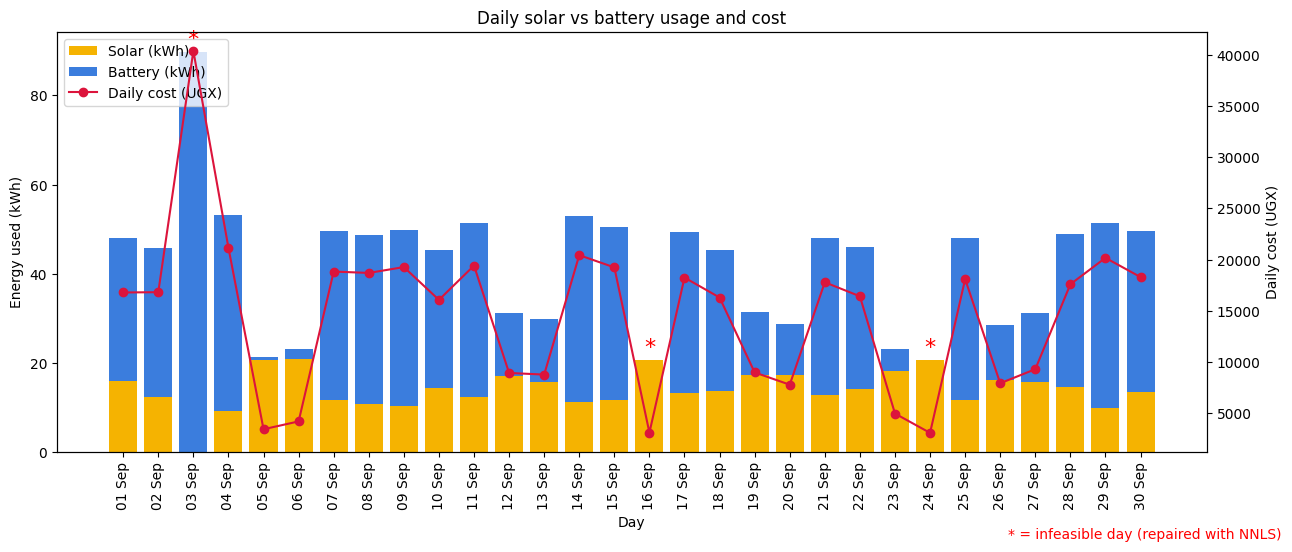

In [19]:
def plot_dispatch(plan_table, cost_series, title="Daily solar vs battery usage and cost"):
    """Stacked bars of solar + battery (left axis) and daily cost line (right axis)."""
    fig, ax = plt.subplots(figsize=(13, 5.5))
    days = np.arange(len(plan_table))

    ax.bar(days, plan_table["solar"], color="#f5b301", label="Solar (kWh)")
    ax.bar(days, plan_table["battery"], bottom=plan_table["solar"],
           color="#3b7ddd", label="Battery (kWh)")

    # Star above infeasible days
    totals = plan_table["solar"] + plan_table["battery"]
    for d in days[~plan_table["feasible"].to_numpy()]:
        ax.text(d, totals.iloc[d] + 1.5, "*", ha="center", color="red", fontsize=16)

    ax.set_xticks(days)
    ax.set_xticklabels(plan_table.index.strftime("%d %b"), rotation=90)
    ax.set_xlabel("Day")
    ax.set_ylabel("Energy used (kWh)")
    ax.set_title(title)

    ax2 = ax.twinx()                                   # second y-axis on the right
    ax2.plot(days, cost_series.to_numpy(), color="crimson", marker="o", label="Daily cost (UGX)")
    ax2.set_ylabel("Daily cost (UGX)")

    # One combined legend
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left")
    fig.text(0.99, 0.01, "* = infeasible day (repaired with NNLS)", ha="right", color="red")

    fig.tight_layout()
    plt.show()

plot_dispatch(plan, cost)

---
# Extension A: `HybridMicroGrid` (adding a diesel generator `z`)

We add **diesel (z)** and a **third constraint** of our choice, an *energy balance*:

| Constraint | Equation |
|---|---|
| Daytime load | `3x + 2y + 1z = D1` |
| Critical load | `4x + 1y + 2z = D2` |
| **Energy balance (our choice)** | `1x + 1y + 1z = D3` |

(Coefficients are illustrative.) Thanks to inheritance, `HybridMicroGrid` reuses all of `MicroGrid` (the checks, `solve_many`, `dispatch`) and only adds what is new.

In [20]:
class HybridMicroGrid(MicroGrid):
    """MicroGrid extended with a diesel generator: a 3x3 system (solar, battery, diesel)."""

    DEFAULT_MATRIX = [[3, 2, 1],
                      [4, 1, 2],
                      [1, 1, 1]]

    def __init__(self, matrix=DEFAULT_MATRIX, labels=("solar", "battery", "diesel")):
        super().__init__(matrix, labels)          # parent does the checks (det, cond, rank)

    def solve_day(self, d1, d2, d3):
        """Solve one day. Returns (solar, battery, diesel) in kWh."""
        return tuple(float(v) for v in self.solve([d1, d2, d3]))

    def solutions_when_dependent(self, demand):
        """For a SINGULAR system: report whether it has infinitely many solutions or none.

        Uses least squares (lstsq). If the residual is ~0, the demands are consistent
        (infinitely many solutions); otherwise the equations contradict each other (none).
        """
        demand = np.asarray(demand, dtype=float)
        best_fit, *_ = np.linalg.lstsq(self.A, demand, rcond=None)
        gap = np.linalg.norm(self.A @ best_fit - demand)
        return best_fit, gap

In [21]:
# 1) A healthy 3x3 system: we planted the answer (20, 15, 10) to prove the solver is right
hybrid = HybridMicroGrid()
hybrid.report()
print("\nDemands (100, 115, 45) ->", hybrid.solve_day(100, 115, 45), "(expected solar=20, battery=15, diesel=10)")

Coefficient matrix A:
[[3. 2. 1.]
 [4. 1. 2.]
 [1. 1. 1.]]

Determinant      : -4.0000
Condition number : 10.0589

-> Well-posed but MODERATELY sensitive: expect noticeable error amplification.

Demands (100, 115, 45) -> (20.0, 15.0, 9.999999999999996) (expected solar=20, battery=15, diesel=10)


### What if the new equation is *linearly dependent* on the others?
Suppose the third equation is just the **sum of the first two**: `7x + 3y + 3z = D3`. It carries **no new information**: the matrix loses a rank, `det = 0`, and `cond` explodes.

In [22]:
dependent = HybridMicroGrid(matrix=[[3, 2, 1],
                                    [4, 1, 2],
                                    [7, 3, 3]])      # row 3 = row 1 + row 2
dependent.report()
print("Rank:", np.linalg.matrix_rank(dependent.A), "(a full 3x3 system would have rank 3)")

try:
    dependent.solve_day(100, 115, 215)
except np.linalg.LinAlgError as error:
    print("\nSolver refused:", error)

Coefficient matrix A:
[[3. 2. 1.]
 [4. 1. 2.]
 [7. 3. 3.]]

Determinant      : 0.0000
Condition number : 24820378054521468.0000

-> SINGULAR: the equations are dependent. No unique solution exists.
Rank: 2 (a full 3x3 system would have rank 3)

Solver refused: This system is singular (dependent equations): no unique solution. Call .report() to see the diagnostics.


A singular system has one of two fates, depending on D3:
* **Consistent** (`D3 = D1 + D2`): the third equation agrees with the first two, so there are **infinitely many solutions**.
* **Inconsistent** (`D3 ≠ D1 + D2`): the equations contradict each other, so there are **no exact solutions**.

In [23]:
# Case 1: consistent -> infinitely many solutions
demand_ok = [100, 115, 215]                          # D3 = D1 + D2
sol_a, gap = dependent.solutions_when_dependent(demand_ok)
slide = null_space(dependent.A)[:, 0]                # the direction we can move without changing any demand
sol_b = sol_a + 3 * slide                            # a completely different solution

print("Consistent demands: gap =", round(gap, 10))
print("  Solution A:", sol_a.round(3), "-> A@v =", (dependent.A @ sol_a).round(3))
print("  Solution B:", sol_b.round(3), "-> A@v =", (dependent.A @ sol_b).round(3))
print("  Same demands, different dispatch: infinitely many solutions.")

# Case 2: inconsistent -> no exact solution
demand_bad = [100, 115, 200]                         # D3 != D1 + D2
sol_c, gap = dependent.solutions_when_dependent(demand_bad)
print(f"\nInconsistent demands: gap = {gap:.3f} (> 0, so no exact solution exists; best fit = {sol_c.round(3)})")

Consistent demands: gap = 0.0
  Solution A: [21.579 13.947  7.368] -> A@v = [100. 115. 215.]
  Solution B: [23.039 12.974  4.935] -> A@v = [100. 115. 215.]
  Same demands, different dispatch: infinitely many solutions.

Inconsistent demands: gap = 8.660 (> 0, so no exact solution exists; best fit = [20.658 12.895  7.237])


**Design lesson:** an extra constraint is only useful if it is **independent**. Always check `det`, `rank` and `cond` *before* trusting a solver.

---
# Extension B: Sensitivity analysis (Monte Carlo)
**Question:** if the demand forecasts are off by up to ±5%, how much do `x` and `y` move?

**Method:** take a typical day (average D1 and D2), run 1,000 random trials where each demand is multiplied by a random factor between 0.95 and 1.05, solve all 1,000 in one vectorised call, and study the spread.

In [24]:
def sensitivity_analysis(micro_grid, demand, pct=0.05, draws=1000, seed=SEED):
    """Monte Carlo test of how demand errors affect the dispatch.

    Returns a dict with the baseline answer, all perturbed answers, and the
    'amplification' of every trial (relative output change / relative input change).
    """
    rng = np.random.default_rng(seed)
    demand = np.asarray(demand, dtype=float)

    factors = rng.uniform(1 - pct, 1 + pct, size=(len(demand), draws))   # e.g. 0.97, 1.04, ...
    noisy = demand[:, None] * factors                                    # perturbed demands
    answers = micro_grid.solve_many(noisy)                               # all trials at once
    base = micro_grid.solve(demand)

    rel_in = np.linalg.norm(noisy - demand[:, None], axis=0) / np.linalg.norm(demand)
    rel_out = np.linalg.norm(answers - base[:, None], axis=0) / np.linalg.norm(base)
    return {"base": base, "answers": answers, "amplification": rel_out / rel_in}

In [25]:
typical_day = D.mean(axis=1)                          # average [D1, D2]
result = sensitivity_analysis(grid, typical_day)

print(f"Typical day demand: D1 = {typical_day[0]:.1f} kWh, D2 = {typical_day[1]:.1f} kWh\n")
for i, name in enumerate(SOURCE_NAMES):
    values = result["answers"][i]
    base_value = result["base"][i]
    print(f"{name:8s} base = {base_value:6.2f} kWh | std = {values.std():5.2f} kWh "
          f"({values.std() / base_value:5.1%} of base) | range = {values.min():.1f} to {values.max():.1f}")

Typical day demand: D1 = 98.1 kWh, D2 = 84.2 kWh

solar    base =  14.07 kWh | std =  1.13 kWh ( 8.0% of base) | range = 11.6 to 16.6
battery  base =  27.93 kWh | std =  2.71 kWh ( 9.7% of base) | range = 21.7 to 34.1


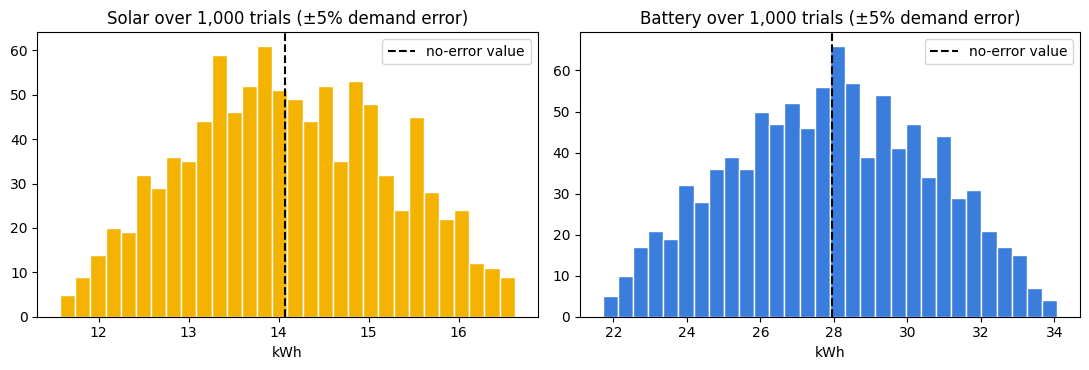

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for i, (name, colour) in enumerate(zip(SOURCE_NAMES, ["#f5b301", "#3b7ddd"])):
    axes[i].hist(result["answers"][i], bins=30, color=colour, edgecolor="white")
    axes[i].axvline(result["base"][i], color="black", linestyle="--", label="no-error value")
    axes[i].set_title(f"{name.title()} over 1,000 trials (±5% demand error)")
    axes[i].set_xlabel("kWh")
    axes[i].legend()
fig.tight_layout()
plt.show()

### Linking the result to the condition number
The theory says: **relative error in the answer ≤ `cond(A)` × relative error in the demands.** So `cond(A)` is the *worst-case* amplification factor. The simulation should never exceed it, and typically sits below it.

In [27]:
amp = result["amplification"]
print(f"Condition number (theoretical worst case) : {grid.cond:.2f}")
print(f"Largest amplification seen in 1,000 trials : {amp.max():.2f}")
print(f"Average amplification                      : {amp.mean():.2f}")
print("Never exceeds the bound:", bool(amp.max() <= grid.cond + 1e-9))

Condition number (theoretical worst case) : 5.83
Largest amplification seen in 1,000 trials : 4.46
Average amplification                      : 2.93
Never exceeds the bound: True


**Interpretation:** a ±5% error in the demand forecasts moves `x` and `y` by a few percent, consistent with the small condition number. This grid is *forgiving*: forecasting errors do not get blown up. If we used a nearly-dependent matrix (large `cond`), the same ±5% could swing the dispatch wildly.

---
## Reuse recipe
Everything above is built from reusable parts. A complete planner for **another** clinic (new matrix, new prices, new CSV) is one function call:

In [28]:
def run_planner(csv_path=CSV_PATH, matrix=COEFF_MATRIX, solar_price=SOLAR_PRICE,
                battery_price=BATTERY_PRICE, method="nnls"):
    """Load a demand CSV, build a MicroGrid, and return (plan table, daily cost, monthly cost)."""
    table = load_demand_csv(csv_path)
    micro_grid = MicroGrid(matrix)
    plan_table = micro_grid.dispatch(to_demand_matrix(table), method=method, index=table["date"])
    cost_series = daily_cost(plan_table, solar_price, battery_price)
    return plan_table, cost_series, cost_series.sum()

# Example: what if battery energy became cheaper (UGX 300/kWh)?
_, _, monthly_now = run_planner()
_, _, monthly_cheap = run_planner(battery_price=300)
print(f"Monthly cost at battery UGX 450/kWh: UGX {monthly_now:,.0f}")
print(f"Monthly cost at battery UGX 300/kWh: UGX {monthly_cheap:,.0f}")
print(f"Saving                              : UGX {monthly_now - monthly_cheap:,.0f}")

Monthly cost at battery UGX 450/kWh: UGX 440,635
Monthly cost at battery UGX 300/kWh: UGX 314,902
Saving                              : UGX 125,733


## Summary of what we learned
1. **Well-posedness:** `det ≠ 0` gives a unique solution; `cond(A)` tells how much input errors get amplified.
2. **Vectorising:** one `solve(A, B)` call with many right-hand sides beats a Python loop, increasingly so as data grows.
3. **Physical feasibility:** maths can return impossible (negative) energy; detect it, then repair it with `nnls` (better than clipping) and still *report* it.
4. **Inheritance:** `HybridMicroGrid` reuses `MicroGrid` and only adds what is new.
5. **Linear dependence:** a redundant equation adds no information, so the system becomes singular (no unique solution).
6. **Sensitivity:** Monte Carlo experiments confirm the theoretical bound given by the condition number.

---
## Findings & Limitations

**Findings.** The system `3x + 2y = D1`, `4x + y = D2` is well-posed (determinant = -5, condition number about 5.8), so every pair of demands has exactly one dispatch and forecast errors can be amplified by at most about 6 times. The Monte Carlo test agreed: with +/-5% demand error the largest amplification was 4.5, below that bound. Solving all 30 days in one vectorised call was roughly 40 times faster than a Python loop, and the gap grew to several hundred times at 100,000 days. Three of the 30 days (10%) were infeasible: two clinic-closed days where critical load was too high relative to daytime load (battery < 0) and one outreach surge day (solar < 0). NNLS left under half the unmet demand that simple clipping left. The battery is the more volatile source (standard deviation about 18.7 kWh, coefficient of variation about 0.67) because its formula puts a weight of 0.8 on the noisy daytime load. The estimated monthly cost is about UGX 440,000, and because battery energy costs three times as much as solar, battery-heavy days are the expensive ones.

**Limitations.** Demand data and prices are synthetic and illustrative, so the costs show the method, not real tariffs. Each day is solved independently: no battery charge level carries over between days, whereas a real planner would model storage over time. Infeasible days still have unmet demand after NNLS, so a real centre would need a generator or load-shedding on those days. The diesel coefficients and the energy-balance equation were chosen for demonstration only. The Monte Carlo test used independent, uniform errors, while real forecast errors are likely to be correlated.